# Laptop Data Exploration

## Business Question
What factors influence laptop prices in the global market?

## Objective
The objective of this notebook is to explore the cleaned laptop dataset, identify patterns and relationships between laptop specifications and prices, and determine which features may be useful for predicting laptop prices.

## Approach
1. **Univariate Analysis:** Examine the distribution of individual variables.
2. **Bivariate Analysis:** Investigate relationships between laptop prices and individual features.
3. **Multivariate Analysis:** Explore how multiple laptop specifications relate to price.


In [1]:
# import necessary dependancies
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#get data
file_path="../data/global-laptop-selling-dataset/clean_global_laptop_selling_data.csv"
laptop_df=pd.read_csv(file_path,index_col="laptop_ID")

In [3]:
# display 5 first rows
laptop_df.head()

,Company,Product,TypeName,Inches,Ram,OpSys,Price_euros,ResolutionWidth,ResolutionHeight,DisplayFeatures,...,CpuModel,ClockSpeed,SSDCapacityGB,HDDCapacityGB,FlashStorageGB,HybridStorageGB,WeightKg,GpuBrand,GpuModel,OsFamily
laptop_ID,,,,,,,,,,,,,,,,,,,,,
1,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1339.69,2560,1600,IPS Panel Retina Display,...,Core i5,2.3,128.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 640,macOS
2,Apple,Macbook Air,Ultrabook,13.3,8,macOS,898.94,1440,900,NaN,...,Core i5,1.8,0.0,0.0,128.0,0.0,1.34,Intel,HD Graphics 6000,macOS
3,HP,250 G6,Notebook,15.6,8,No OS,575.00,1920,1080,Full HD,...,Core i5 7200U,2.5,256.0,0.0,0.0,0.0,1.86,Intel,HD Graphics 620,No OS
4,Apple,MacBook Pro,Ultrabook,15.4,16,macOS,2537.45,2880,1800,IPS Panel Retina Display,...,Core i7,2.7,512.0,0.0,0.0,0.0,1.83,AMD,Radeon Pro 455,macOS
5,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1803.60,2560,1600,IPS Panel Retina Display,...,Core i5,3.1,256.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 650,macOS


In [4]:
# get summary of the data
laptop_df.info()

<class 'pandas.DataFrame'>
Index: 1303 entries, 1 to 1320
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   str    
 1   Product           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   Ram               1303 non-null   int64  
 5   OpSys             1303 non-null   str    
 6   Price_euros       1303 non-null   float64
 7   ResolutionWidth   1303 non-null   int64  
 8   ResolutionHeight  1303 non-null   int64  
 9   DisplayFeatures   989 non-null    str    
 10  CpuBrand          1303 non-null   str    
 11  CpuModel          1303 non-null   str    
 12  ClockSpeed        1303 non-null   float64
 13  SSDCapacityGB     1303 non-null   float64
 14  HDDCapacityGB     1303 non-null   float64
 15  FlashStorageGB    1303 non-null   float64
 16  HybridStorageGB   1303 non-null   float64
 17  WeightKg   

In [5]:
# statistical summary of data
laptop_df.describe()

,Inches,Ram,Price_euros,ResolutionWidth,ResolutionHeight,ClockSpeed,SSDCapacityGB,HDDCapacityGB,FlashStorageGB,HybridStorageGB,WeightKg
count,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000
mean,15.017191,8.382195,1123.686992,1894.784344,1070.830391,2.298772,184.027629,422.477360,4.555641,9.034536,2.038734
std,1.426304,5.084665,699.009043,494.641028,284.519410,0.506340,188.268689,528.006298,30.274090,94.738890,0.665475
min,10.100000,2.000000,174.000000,1366.000000,768.000000,0.900000,0.000000,0.000000,0.000000,0.000000,0.690000
25%,14.000000,4.000000,599.000000,1600.000000,900.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.500000
50%,15.600000,8.000000,977.000000,1920.000000,1080.000000,2.500000,256.000000,0.000000,0.000000,0.000000,2.040000
75%,15.600000,8.000000,1487.880000,1920.000000,1080.000000,2.700000,256.000000,1024.000000,0.000000,0.000000,2.300000
max,18.400000,64.000000,6099.000000,3840.000000,2160.000000,3.600000,1024.000000,2048.000000,512.000000,1024.000000,4.700000


## Univariate analysis

#### Distribution of Laptops by Company

This analysis examines the number of laptops produced by each company in the dataset. The goal is to identify which companies are most represented and which have the fewest laptops in the dataset.

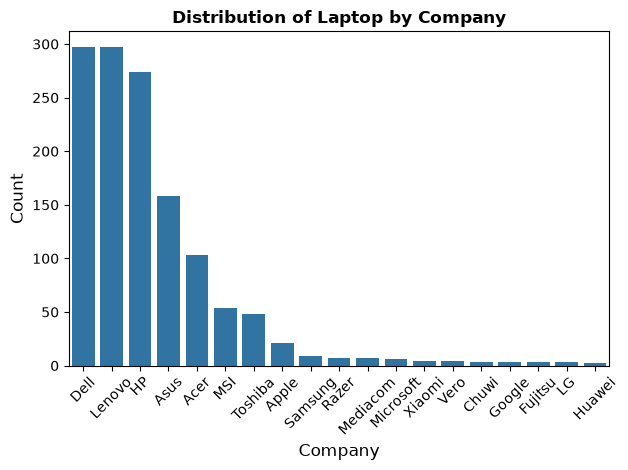

In [6]:
fig,ax=plt.subplots()
company_order=laptop_df["Company"].value_counts().index

sns.countplot(data=laptop_df,x="Company",order=company_order ,ax=ax)
ax.set_xlabel("Company",fontsize=12)
ax.set_ylabel("Count",fontsize=12)
ax.set_title("Distribution of Laptop by Company",fontsize=12,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** Lenovo and Dell have the highest number of laptops in the dataset, while Huawei has the lowest representation.

### Distribution of Laptops by Type

This analysis examines the number of laptops in each product type to identify which types are most represented and which have the fewest entries in the dataset.


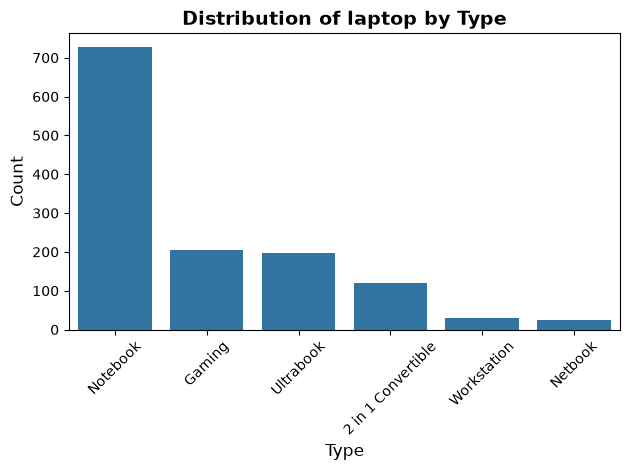

In [7]:
fig,ax=plt.subplots()
type_order =laptop_df["TypeName"].value_counts().index
sns.countplot(data=laptop_df,x="TypeName",order=type_order,ax=ax)
ax.set_ylabel("Count",fontsize=12)
ax.set_xlabel("Type",fontsize=12)
ax.set_title("Distribution of laptop by Type",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()


**Observation:** Notebook is the most common laptop type in the dataset, while Netbook is the least common.

#### Distribution of laptops by inches
This analysis examine the distribution of laptops by inches

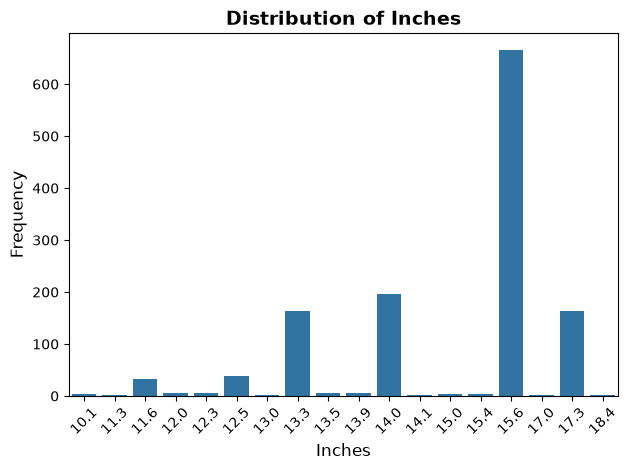

In [8]:
fig,ax=plt.subplots()
sns.countplot(data=laptop_df,x="Inches",ax=ax)
ax.set_xlabel("Inches",fontsize=12)
ax.set_ylabel("Frequency",fontsize=12)
ax.set_title("Distribution of Inches",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Distribution of laptop by RAM
This analysis examine distribution of laptop by ram to indentify which ram is most common and which is least common

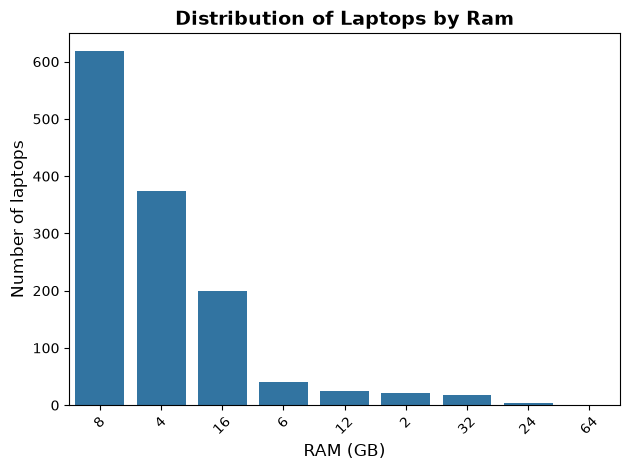

In [9]:
fig,ax=plt.subplots()
ram_order=laptop_df["Ram"].value_counts().index
sns.countplot(data=laptop_df,x="Ram",order=ram_order,ax=ax)
ax.set_xlabel("RAM (GB)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Ram",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation** 8GB RAM is the most common followed by 4 while 64GB RAM is least common followed by 24GB

#### Distribution of laptops by operating system
This analysis examine the distribution of laptops by operating system to find which is the most common operating system and which is the least

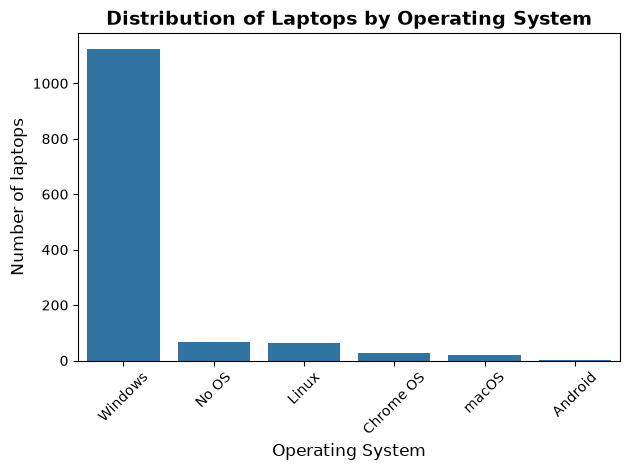

In [10]:
fig,ax=plt.subplots()
os_order=laptop_df["OsFamily"].value_counts().index
sns.countplot(data=laptop_df,x="OsFamily",order=os_order,ax=ax)
ax.set_xlabel("Operating System",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Operating System",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
laptop_df["OsFamily"].value_counts()

OsFamily
Windows      1125
No OS          66
Linux          62
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

**Observation** Windows is the most common operating system with 1125 laptops  while Android is the least common with 2 laptops

#### Distribution of Laptop price
This analysis examines the distribution of laptop price

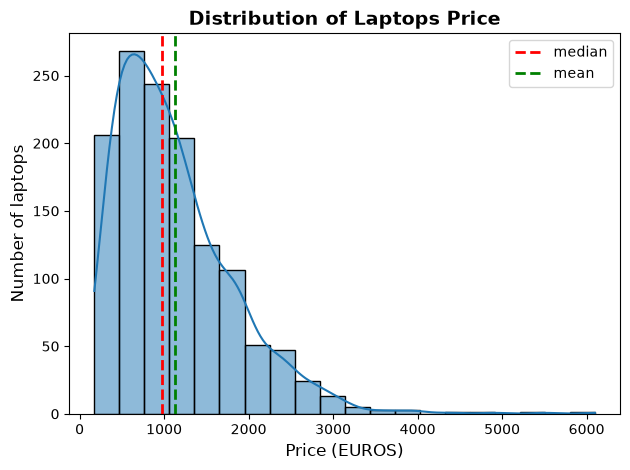

In [12]:
fig,ax=plt.subplots()
sns.histplot(data=laptop_df,x="Price_euros",bins=20,kde=True,ax=ax)
median=laptop_df["Price_euros"].median()
mean=laptop_df["Price_euros"].mean()
ax.axvline(median,color="red",linestyle="--",linewidth=2,label="median")
ax.axvline(mean,color="green",linestyle="--",linewidth=2,label="mean")
ax.set_xlabel("Price (EUROS)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops Price",fontsize=14,fontweight="bold")
ax.legend()

plt.tight_layout()
plt.show()

**Observation** 
- Laptop price is right skewed with median less than mean
- Typical laptop price is around 1000 but there are outliers with laptops up to 6000

#### Distribution of Weight by Laptops
This examine the distribution of laptops weight

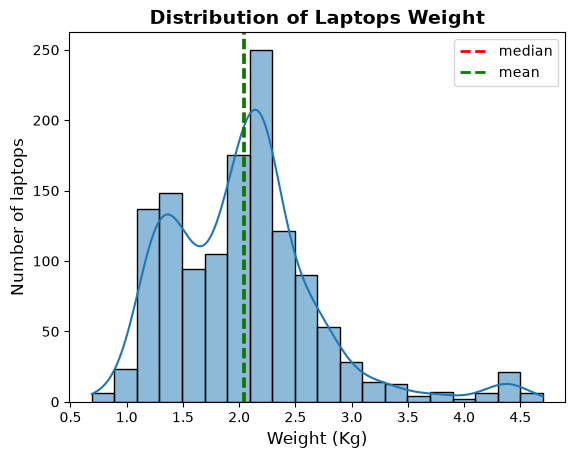

In [13]:
fig,ax=plt.subplots()
sns.histplot(data=laptop_df,x="WeightKg",bins=20,kde=True,ax=ax)
median=laptop_df["WeightKg"].median()
mean=laptop_df["WeightKg"].mean()
ax.axvline(median,color="red",linestyle="--",linewidth=2,label="median")
ax.axvline(mean,color="green",linestyle="--",linewidth=2,label="mean")
ax.set_xlabel("Weight (Kg)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops Weight",fontsize=14,fontweight="bold")
ax.legend()

In [14]:
laptop_df["WeightKg"].describe()

count    1303.000000
mean        2.038734
std         0.665475
min         0.690000
25%         1.500000
50%         2.040000
75%         2.300000
max         4.700000
Name: WeightKg, dtype: float64

**Observation**
- Laptop weight is bimodal  with one peak around 1.2 to 1.4kg and larger one around 2.0 to 2.3kg
- The mean and median overlap with mean of 2.04 and median of 2.04 so the distribution is roughly balanced rather than strong skewed
- Most laptop weight between 1.0 and 3.0kg

#### Distribution of Laptop Storage

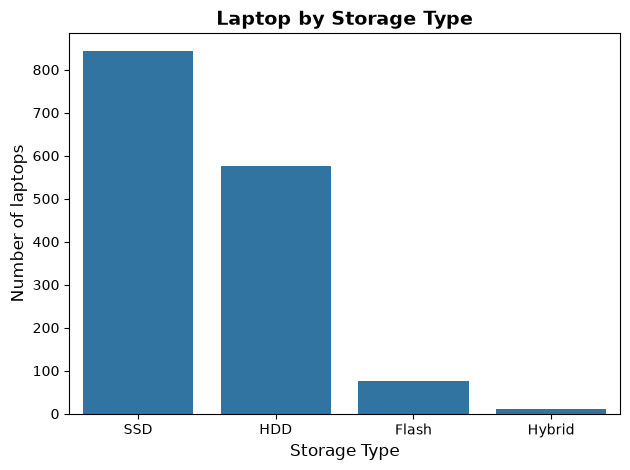

In [15]:
storage_cols= [
"SSDCapacityGB" ,  
"HDDCapacityGB"   ,  
"FlashStorageGB"  , 
"HybridStorageGB"  ] 
labels = ["SSD", "HDD", "Flash", "Hybrid"]

count=(laptop_df[storage_cols] >0).sum().values
fig,ax=plt.subplots()
sns.barplot(x=labels,y=count,ax=ax)


ax.set_xlabel("Storage Type",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Laptop by Storage Type",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()


**Observation**
- SSD is the most common storage
- Hybrid is the least common storage

#### Resolution

 ### Distribution of Resolution Width





In [16]:
laptop_df["ResolutionWidth"].value_counts()

ResolutionWidth
1920    846
1366    308
3840     43
2560     29
3200     27
1600     23
2304      6
2256      6
1440      4
2880      4
2400      4
2160      2
2736      1
Name: count, dtype: int64

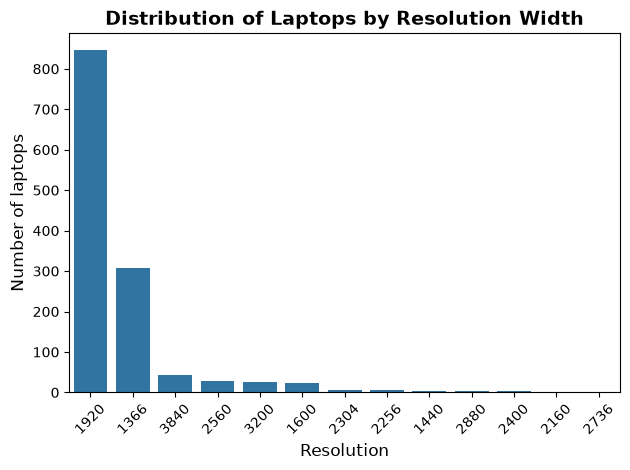

In [17]:
fig,ax=plt.subplots()
resolution_order=laptop_df["ResolutionWidth"].value_counts().index
sns.countplot(data=laptop_df,x="ResolutionWidth",order=resolution_order,ax=ax)
ax.set_xlabel("Resolution",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Resolution Width",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** A resolution Width of 1920 pixels is the most common, followed by 1366 pixels. A Width of 2736 pixels is the least common among the displayed values.

In [18]:
laptop_df["ResolutionHeight"].value_counts()

ResolutionHeight
1080    841
768     308
2160     43
1800     31
1440     31
900      27
1600     10
1504      6
1200      5
1824      1
Name: count, dtype: int64

#### Distribution of Resolution Height

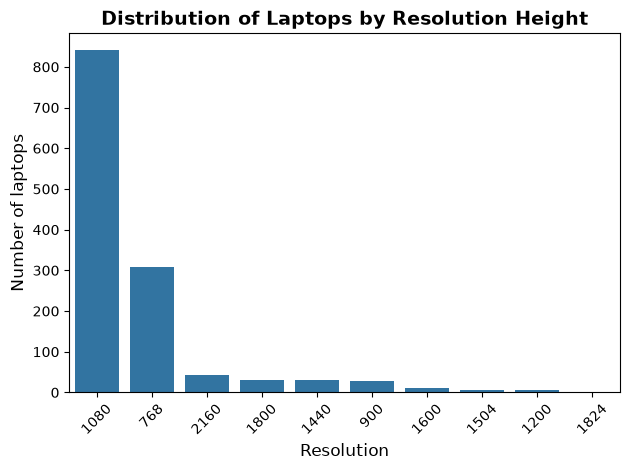

In [19]:
fig,ax=plt.subplots()
resolution_order=laptop_df["ResolutionHeight"].value_counts().index
sns.countplot(data=laptop_df,x="ResolutionHeight",order=resolution_order,ax=ax)
ax.set_xlabel("Resolution",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Resolution Height",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation**: A resolution height of 1080 pixels is the most common, followed by 768 pixels. A height of 1824 pixels is the least common among the displayed values.

## Bivarent

In [20]:
laptop_df.columns

Index(['Company', 'Product', 'TypeName', 'Inches', 'Ram', 'OpSys',
       'Price_euros', 'ResolutionWidth', 'ResolutionHeight', 'DisplayFeatures',
       'CpuBrand', 'CpuModel', 'ClockSpeed', 'SSDCapacityGB', 'HDDCapacityGB',
       'FlashStorageGB', 'HybridStorageGB', 'WeightKg', 'GpuBrand', 'GpuModel',
       'OsFamily'],
      dtype='str')

#### What the relationship between company and laptop price
This examine  laptop Price by company

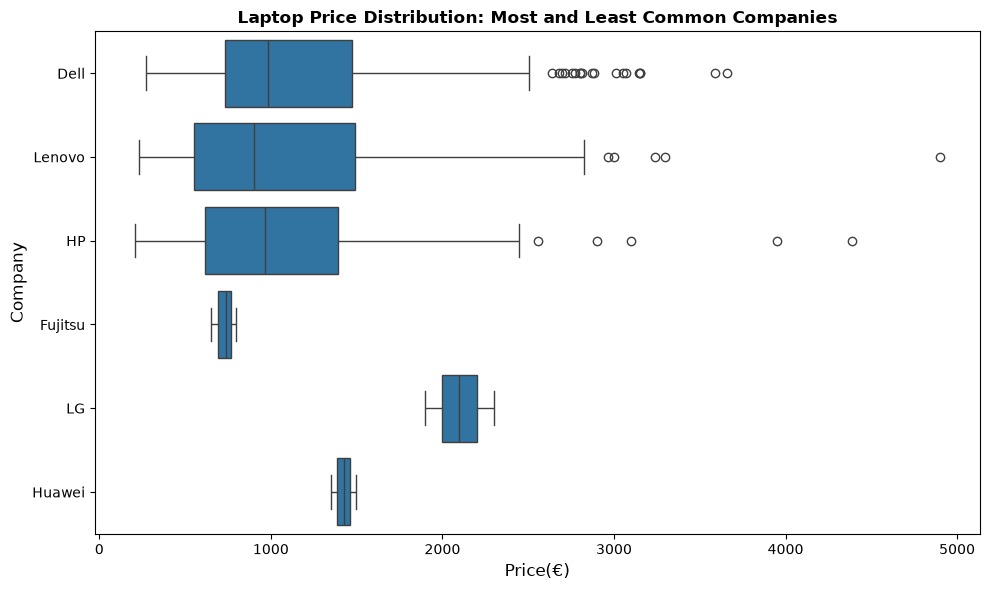

In [ ]:
# count laptops per company
companies_count=laptop_df["Company"].value_counts()

# company with most laptops
top_3_companies=companies_count.head(3).index.to_list()
#companies with least laptops
bottom_3_companies=companies_count.tail(3).index.to_list()

#merge highest and lowest
companies=top_3_companies+bottom_3_companies



fig,ax=plt.subplots(figsize=(10,6))
sns.boxplot(data=laptop_df[laptop_df["Company"].isin(companies)], x="Price_euros", y="Company", order=companies, ax=ax)
ax.set_xlabel("Price(€)",fontsize=12)
ax.set_ylabel("Company",fontsize=12)
ax.set_title("Laptop Price Distribution: Most and Least Common Companies",fontweight="bold")
plt.tight_layout()
plt.show()

In [68]:
companies_count

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64


**Observation**
- Typical price varies by company . The three most common companies (Dell, Lenovo, HP) have almost similar medians of roughly €900-1,000.
- Their price ranges are wide, from about €250 to over €2,500 without outliers
- All three have many high-price outliers, and their distributions are right skewed
- The three least common companies (Fujitsu, LG, Huawei; n = 3, 3, 2) have narrow boxes and no visible outliers, but with so few laptops this reflects limited data rather than genuine price consistency, so no firm conclusion can be drawn about them.
- Company is clearly related to price, but comparisons are only reliable for companies with enough laptops.


#### Does laptop price and type name have a relationship


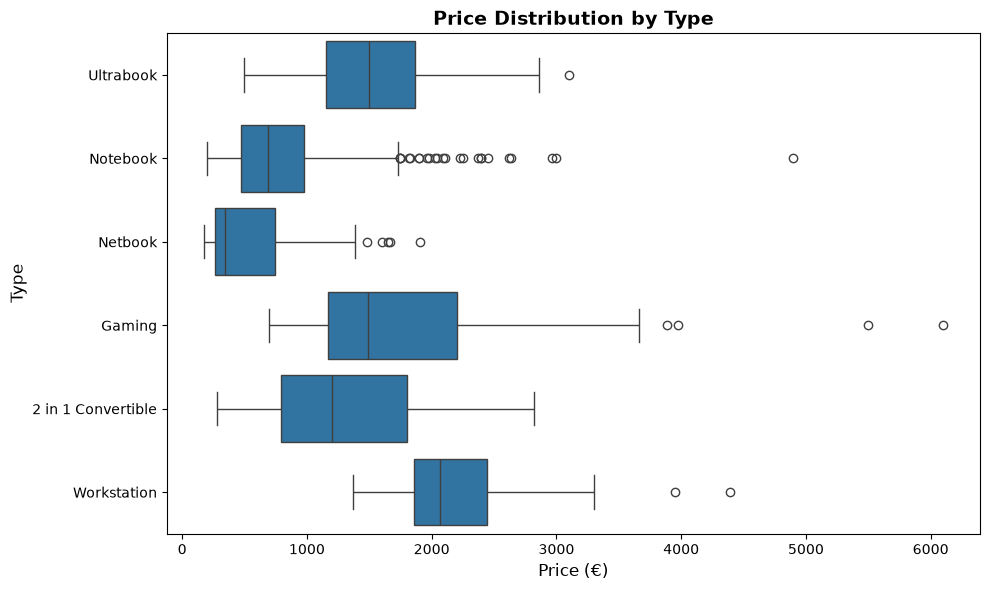

In [77]:
fig,ax=plt.subplots(figsize=(10,6))
sns.boxplot(data=laptop_df,x="Price_euros",y="TypeName",ax=ax)
ax.set_xlabel("Price (€)",fontsize=12)
ax.set_ylabel("Type",fontsize=12)
ax.set_title("Price Distribution by Type",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()

In [73]:
laptop_df.groupby("TypeName")["Price_euros"].median()

TypeName
2 in 1 Convertible    1199.0
Gaming                1492.8
Netbook                340.0
Notebook               691.0
Ultrabook             1499.0
Workstation           2064.9
Name: Price_euros, dtype: float64

In [74]:
laptop_df["TypeName"].value_counts()

TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

**Observation**
1. price varies by Type e.g netbook has median of about €340 while workstation has median of around €2064

2. Most types are right skewed, which supports using the median. Ultrabook  look more symmetrical, and 2 in 1 has no high outliers.
3. Overall, type is clearly related to price

#### Is there a relationship between laptop price and inches


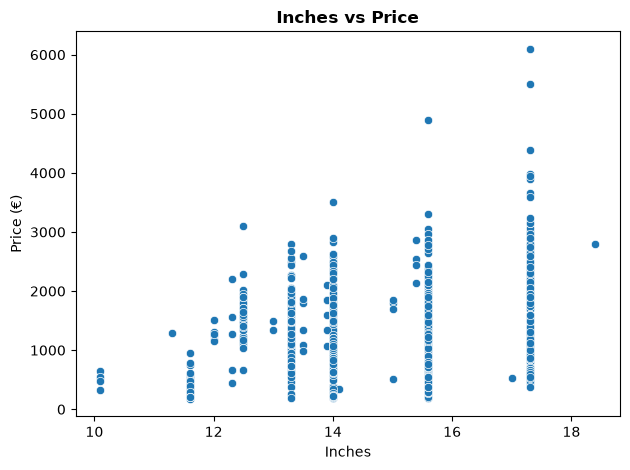

In [83]:
fig,ax=plt.subplots()
sns.scatterplot(data=laptop_df,x="Inches",y="Price_euros",ax=ax)
ax.set_title("Inches vs Price",fontsize=12,fontweight="bold")
ax.set_ylabel("Price (€)")
ax.set_xlabel("Inches")
plt.tight_layout()
plt.show()

In [84]:
laptop_df["Inches"].corr(laptop_df["Price_euros"])

np.float64(0.06819666592963931)

**Observation**

- There is weak correlation between Inches and Price
- Price rise a bit with inches but relationship is not clear at every size there is a wide spread

#### Is there a relationship between RAM and price

In [88]:
# count values per ram
laptop_df["Ram"].value_counts()

Ram
8     619
4     375
16    200
6      41
12     25
2      22
32     17
24      3
64      1
Name: count, dtype: int64

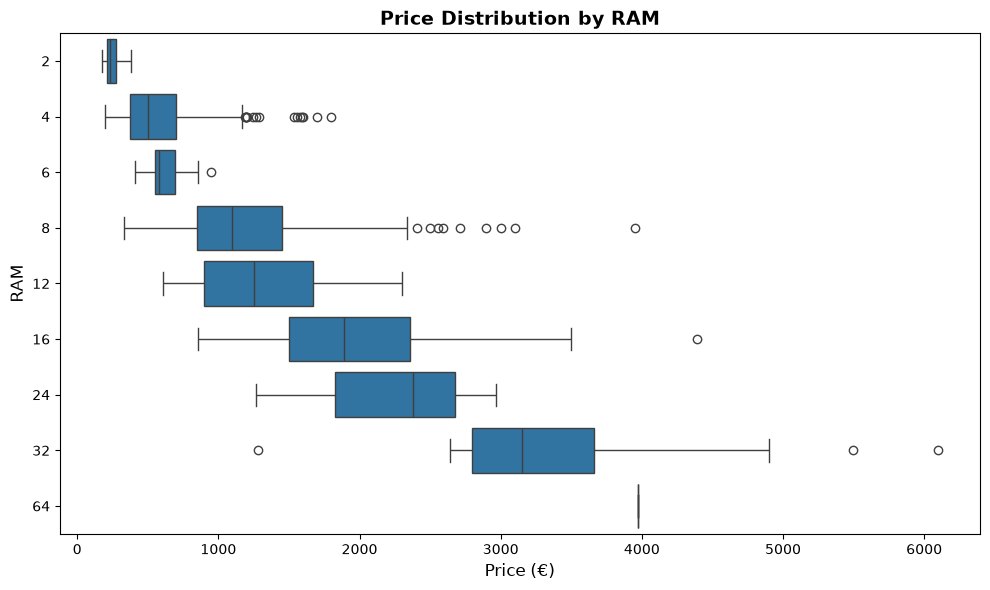

In [99]:
#visualization for distribution of price by ram
fig,ax=plt.subplots(figsize=(10,6))
sns.boxplot(data=laptop_df,x="Price_euros",y="Ram",orient="h",ax=ax)
ax.set_title("Price Distribution by RAM",fontsize=14,fontweight="bold")
ax.set_xlabel("Price (€)",fontsize=12)
ax.set_ylabel("RAM",fontsize=12)
plt.tight_layout()
plt.show()

**Observation**
1. Laptop price vary by RAM with highest Ram having highest median price(€3100)  and lowest RAM Having lowest median price(€250)
2. 64 and 24GB Ram cannot be relies on since thet have 1 and 3 laptops respectively
3. All RAMS are right skewed expect 12GB that is left skewed
4. 

#### Is there a relationship between Price and operating System

In [101]:
# count number of values in each operating system
laptop_df["OsFamily"].value_counts()

OsFamily
Windows      1125
No OS          66
Linux          62
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

Text(0, 0.5, 'Operating System')

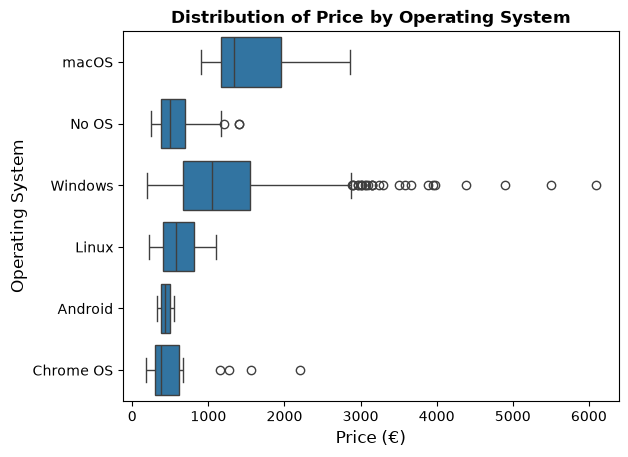

In [106]:
# visualize distribution of price by operating system
fig,ax=plt.subplots()
sns.boxplot(data=laptop_df,x="Price_euros",y="OsFamily",ax=ax)
ax.set_title("Distribution of Price by Operating System",fontweight="bold",fontsize=12)
ax.set_xlabel("Price (€)",fontsize=12)
ax.set_ylabel("Operating System",fontsize=12)


**Observation**
1. Price varies by Operating System
2. Android is unrealible since it has 2 laptops
3. All operating system price is right skewed
4. no operating system,windows and chrome have outliers
5. There is a relationship between price and operating system

#### Is there a relationship between Weight and price

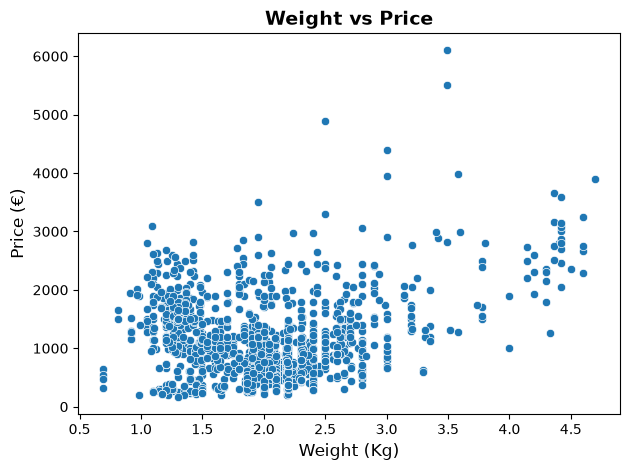

In [117]:
# visualization to compare price and weight
fig,ax=plt.subplots()
sns.scatterplot(data=laptop_df,x="WeightKg",y="Price_euros",ax=ax)
ax.set_ylabel("Price (€)",fontsize=12)
ax.set_xlabel("Weight (Kg)",fontsize=12)
ax.set_title("Weight vs Price",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()


In [115]:
laptop_df["WeightKg"].corr(laptop_df["Price_euros"])

np.float64(0.2103697989168717)

**Observation**
1. There is weak relationship between weight and price

#### is there a relationship between price and resolution

#### Resolution width

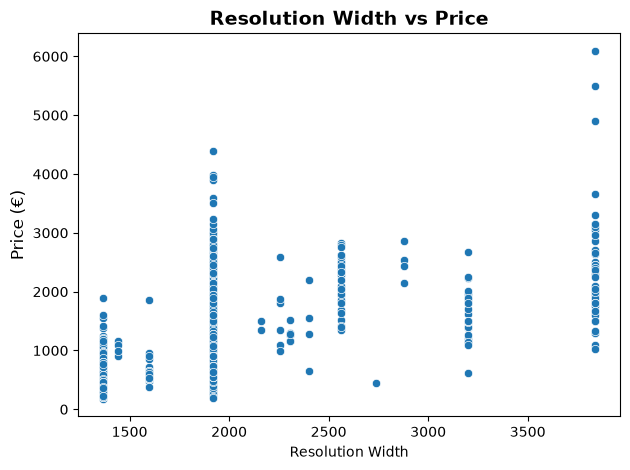

In [119]:
# visualize the relationship between price and width resolution
fig,ax=plt.subplots()
sns.scatterplot(data=laptop_df,x="ResolutionWidth",y="Price_euros",ax=ax)
ax.set_title("Resolution Width vs Price",fontweight="bold",fontsize="14")
ax.set_ylabel("Price (€)",fontsize=12)
ax.set_xlabel("Resolution Width")
plt.tight_layout()
plt.show()

In [122]:
laptop_df["ResolutionWidth"].corr(laptop_df["Price_euros"])

np.float64(0.5565293287169806)

#### Resolution Height

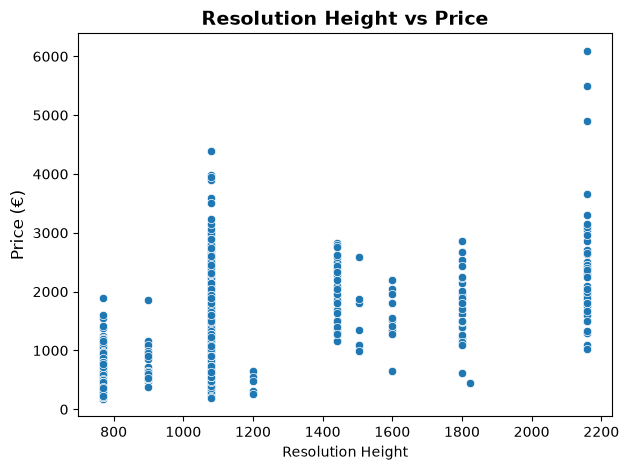

In [124]:
# visualize the relationship between price and Height resolution
fig,ax=plt.subplots()
sns.scatterplot(data=laptop_df,x="ResolutionHeight",y="Price_euros",ax=ax)
ax.set_title("Resolution Height vs Price",fontweight="bold",fontsize="14")
ax.set_ylabel("Price (€)",fontsize=12)
ax.set_xlabel("Resolution Height")
plt.tight_layout()
plt.show()

In [123]:
laptop_df["ResolutionHeight"].corr(laptop_df["Price_euros"])

np.float64(0.5528092198175057)

**Observation**
1. There is moderate positive  correlation between resolution width and price
2. There is moderate positive  correlation between resolution height and price

In [125]:
laptop_df.columns

Index(['Company', 'Product', 'TypeName', 'Inches', 'Ram', 'OpSys',
       'Price_euros', 'ResolutionWidth', 'ResolutionHeight', 'DisplayFeatures',
       'CpuBrand', 'CpuModel', 'ClockSpeed', 'SSDCapacityGB', 'HDDCapacityGB',
       'FlashStorageGB', 'HybridStorageGB', 'WeightKg', 'GpuBrand', 'GpuModel',
       'OsFamily'],
      dtype='str')

#### Is there a relationship between CPU brand and price

In [126]:
laptop_df["CpuBrand"].value_counts()

CpuBrand
Intel      1240
AMD          62
Samsung       1
Name: count, dtype: int64

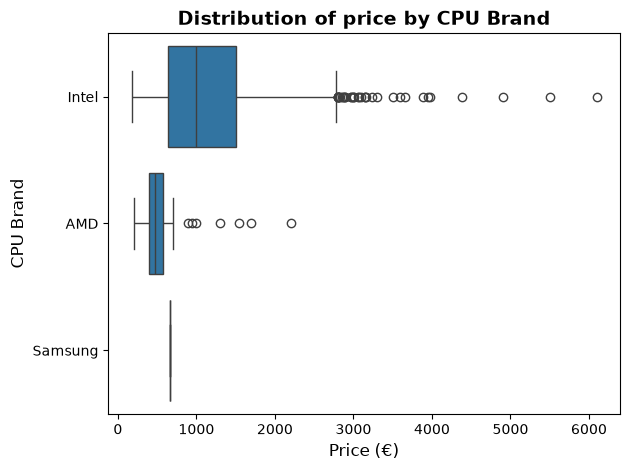

In [131]:
# visualization
fig,ax=plt.subplots()
sns.boxplot(data=laptop_df,x="Price_euros",y="CpuBrand",ax=ax)
ax.set_title("Distribution of price by CPU Brand",fontweight="bold",fontsize=14)
ax.set_xlabel("Price (€)",fontsize=12)
ax.set_ylabel("CPU Brand",fontsize=12)
plt.tight_layout()
plt.show()


**Observation**
1. Price varies by CPU Brand intel has typical price of around €1000 while AMD around €500
2. Samsung brand is unrealible since it has one laptop
3. Both Intel and AMD have outliers on the right 
4. there is relationship between cpu brand and price

#### Is there a relationship between CPU Clock speed and price

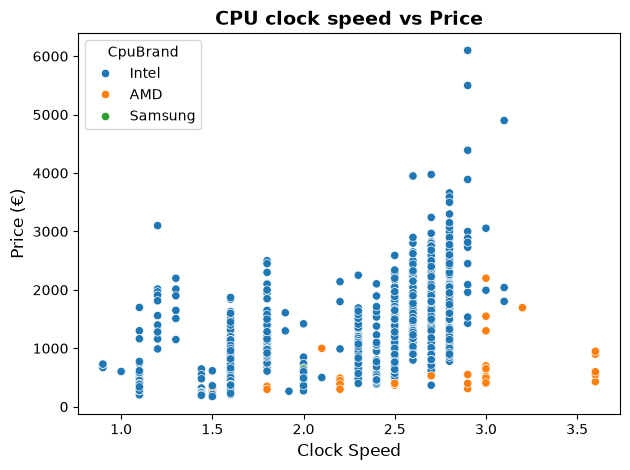

In [ ]:
#visualization
fig,ax=plt.subplots()
sns.scatterplot(data=laptop_df,x="ClockSpeed",y="Price_euros",ax=ax)
ax.set_xlabel("Clock Speed",fontsize=12)
ax.set_ylabel("Price (€)",fontsize=12)
ax.set_title("CPU clock speed vs Price",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()


In [140]:
laptop_df["ClockSpeed"].corr(laptop_df["Price_euros"])

np.float64(0.43029310197031134)

**Observation**
1. There is moderate positive correlation between CPU clock speed and price

#### Is there any relationship between GPU brand and price

In [141]:
laptop_df["GpuBrand"].value_counts()

GpuBrand
Intel     722
Nvidia    400
AMD       180
ARM         1
Name: count, dtype: int64

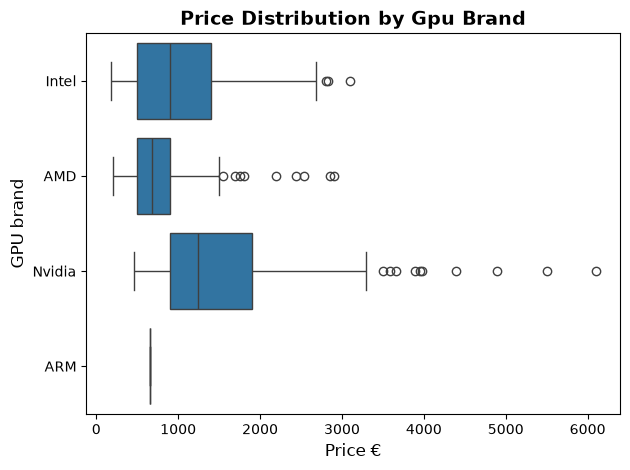

In [144]:
# visualization
fig,ax=plt.subplots()
sns.boxplot(data=laptop_df,x="Price_euros",y="GpuBrand",ax=ax)
ax.set_title("Price Distribution by Gpu Brand",fontweight="bold",fontsize="14")
ax.set_xlabel("Price €",fontsize=12)
ax.set_ylabel("GPU brand",fontsize=12)
plt.tight_layout()
plt.show()

**Observation**
1. price varies by GPU brand
2. ARM brand is too small to plot boxplot
3. All Gpu brand have right outliers meaning  gpu brand have higher prices
4. Intel,AMD,Nvidia are right skewed


### Multivariate

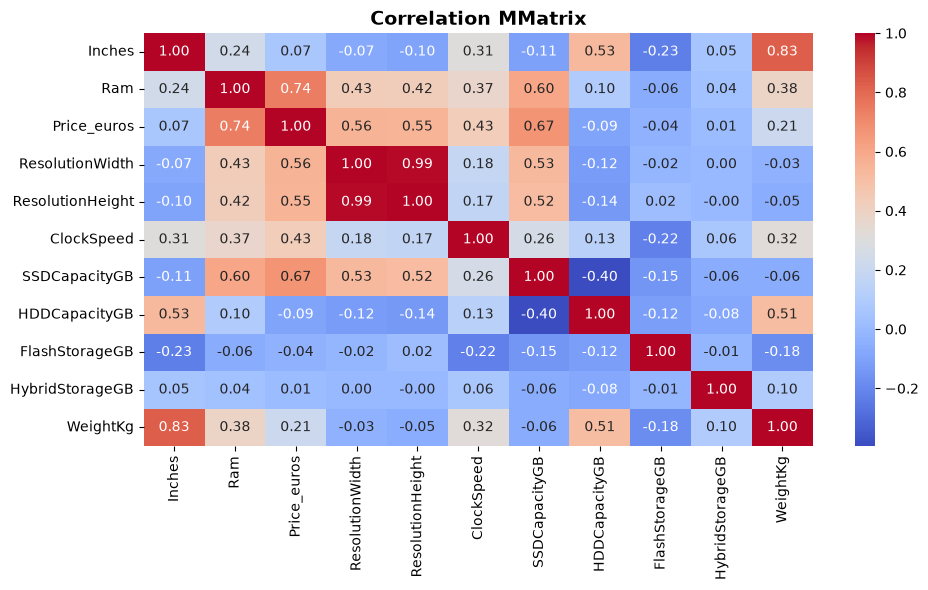

In [ ]:
corrMatrix=laptop_df.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(10,6))
sns.heatmap(data=corrMatrix,annot=True,cmap="coolwarm",fmt=".2f",ax=ax)
ax.set_title("Correlation Matrix",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()

**Observation**
1. There is multicolinerity between resolution width and resolution height
2. There multicolinerity between inches and weight
3. Flash and Hybrid are almost unrelated to everything. They are mostly zeros, so they will add little as numeric features.

Factors correlated with price:
- RAM 0.74
- SSD capacity 0.67
- Resolution width 0.56 and height 0.55
- Clock speed 0.43


**Solution**
- Combine `Resolution Width` and `Resolution Height` into pixels
- Drop `Inches` and keep `Weight` because it correlate more withprice

